# 04 - Gate netlists, 200 shared corners and the gate-level SPICE reference (Part B, steps 3 and 5)

Self-contained notebook: everything it needs is defined below. The only external inputs are the model file, ngspice and the usual Python libraries.

1. **Gates:** INV, NAND2, NOR2, AND2 and OR2 as transistor-level netlists with a documented sizing; one example netlist per gate in `netlists/`.
2. **Corners:** 200 random corners (VDD, temperature and process parameters), drawn once and stored in `data/corners.csv`. The same corners are used for the gates here and for the test circuit later.
3. **SPICE reference:** every gate, every input combination and every corner (3,600 operating points), with the supply and input currents and the internal and output node voltages (`data/gate_spice.csv`).

These results are for evaluation only; no model is trained on them.

## 1. Configuration
Assignment: model file `16nm_HP`, nominal VDD 0.9 V, channel length 16 nm. The ranges follow section 4 of the spec.

In [1]:
import json
import re
import shutil
import subprocess
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODEL_FILE = ROOT / "Model Files-20261105" / "models" / "16nm_HP.pm"     # assigned model file
BUILD_DIR = ROOT / "build"          # scratch space for generated netlists (git-ignored)
NETLIST_DIR = ROOT / "netlists"
DATA_DIR = ROOT / "data"
RESULT_DIR = ROOT / "results"

VDD_NOM = 0.9
LMIN = 16e-9                        # channel length = feature size of the node
WMIN = LMIN                         # smallest allowed width (1 x Lmin); the spec allows 1 to 8 x Lmin
LDIFF = 2 * LMIN                    # diffusion length for the junction areas AD = AS = W * LDIFF (as in the datasets)
VDD_VAR = 0.10                      # VDD uniform in nominal +/- 10 %
TEMP_RANGE = (-40.0, 125.0)         # degC, uniform
PROC_VAR = 0.10                     # process parameters uniform in nominal +/- 10 %
PROC_PARAMS = ("vth0", "toxe", "ndep", "u0", "xj")

N_CORNERS = 200
CORNER_SEED = 20261105 + 100        # the datasets use 20261105 + 0..3
SPICE_OPTIONS = ".options gmin=1e-18 abstol=1e-18 reltol=1e-6 vntol=1e-9"   # required in every netlist
NUMDGT = 15                         # printed digits; the default 6 would round the currents
N_WORKERS = 8                       # parallel ngspice processes
print(f"model {MODEL_FILE.name} | exists: {MODEL_FILE.exists()} | nominal VDD {VDD_NOM} V | L = Wmin = {LMIN * 1e9:.0f} nm | {N_CORNERS} corners")

model 16nm_HP.pm | exists: True | nominal VDD 0.9 V | L = Wmin = 16 nm | 200 corners


## 2. Nominal process parameters and ngspice wrapper
The nominal values are read straight from the `.model` cards (NMOS and PMOS separately). The wrapper runs ngspice natively if it is on the PATH, otherwise through WSL (Windows); only stdout is parsed.

In [2]:
def read_cards(path):
    """Return {card_name: text}; continuation lines ('+') are joined to their .model line."""
    cards, cur = {}, None
    for raw in Path(path).read_text().splitlines():
        s = raw.strip()
        if not s or s.startswith("*"):
            continue
        if s.lower().startswith(".model"):
            cur = s.split()[1].lower()
            cards[cur] = [s]
        elif s.startswith("+") and cur:
            cards[cur].append(s[1:])
        else:
            cur = None
    return {k: " ".join(v) for k, v in cards.items()}


_NUM = r"[-+]?[0-9]*\.?[0-9]+(?:[eE][-+]?[0-9]+)?"


def nominal_values(path, params):
    """Return {card_name: {param: value}} for the requested parameters."""
    out = {}
    for name, text in read_cards(path).items():
        vals = {}
        for p in params:
            m = re.search(rf"(?<![\w.]){p}\s*=\s*({_NUM})", text, re.I)      # (?<![\w.]) keeps 'vth0' from matching inside 'lvth0'
            if m is None:
                raise ValueError(f"parameter {p} not found in card {name}")
            vals[p] = float(m.group(1))
        out[name] = vals
    return out


NOMINAL = nominal_values(MODEL_FILE, PROC_PARAMS)


def to_wsl(path):
    p = Path(path).resolve()
    return "/mnt/" + p.drive.rstrip(":").lower() + "/" + "/".join(p.parts[1:])


def prepare_build():
    """Create the scratch directory and copy the model file there (no spaces in the path)."""
    BUILD_DIR.mkdir(exist_ok=True)
    dst = BUILD_DIR / MODEL_FILE.name
    if not dst.exists() or dst.read_bytes() != MODEL_FILE.read_bytes():
        shutil.copyfile(MODEL_FILE, dst)
    return BUILD_DIR


def run_ngspice(cir_name, cwd, merge_stderr=False):
    """Run `ngspice -b cir_name` inside cwd and return its output as text."""
    cwd = Path(cwd)
    if shutil.which("ngspice"):
        r = subprocess.run(["ngspice", "-b", str(cir_name)], cwd=cwd, capture_output=True, text=True, errors="replace")
        return (r.stdout + (r.stderr if merge_stderr else "")).replace("\x00", "")
    cmd = f"cd '{to_wsl(cwd)}' && ngspice -b '{cir_name}'" + (" 2>&1" if merge_stderr else " 2>/dev/null")
    r = subprocess.run(["wsl", "-e", "bash", "-c", cmd], capture_output=True, text=True, errors="replace")
    return r.stdout.replace("\x00", "")


def ngspice_version():
    if shutil.which("ngspice"):
        r = subprocess.run(["ngspice", "--version"], capture_output=True, text=True, errors="replace")
        text = r.stdout + r.stderr
    else:
        r = subprocess.run(["wsl", "-e", "bash", "-c", "ngspice --version 2>&1"], capture_output=True, text=True, errors="replace")
        text = r.stdout.replace("\x00", "")
    m = re.search(r"ngspice-\d+(?:\.\d+)?", text)
    return m.group(0) if m else "unknown"


print("simulator:", ngspice_version())
pd.DataFrame(NOMINAL).T

simulator: ngspice-42


,vth0,toxe,ndep,u0,xj
nmos,0.47965,9.500000e-10,7.000000e+18,0.030,5.000000e-09
pmos,-0.43121,1.000000e-09,5.500000e+18,0.006,5.000000e-09


## 3. Gates and sizing
Standard static CMOS. **AND2 is a NAND2 followed by an INV, OR2 a NOR2 followed by an INV** (simulated as one netlist). Inputs are `A`, `B` (pattern `AB`: the first digit is `A`), each held at exactly 0 or VDD.

**Sizing** (all widths are between 1 and 8 x Lmin as the spec requires), following the convention of the course slides (inverter `Wp = 2 Wn`, devices in a series stack scaled by the stack height) with a drive-strength multiplier `XX`:

| gate | NMOS | PMOS |
|---|---|---|
| INV | XX x Wmin | 2 XX x Wmin |
| NAND2 | 2 XX x Wmin (series pair) | 2 XX x Wmin |
| NOR2 | XX x Wmin | 4 XX x Wmin (series pair) |
| AND2, OR2 | the NAND2 / NOR2 above, then an INV (XX x Wmin / 2 XX x Wmin) | |

**`XX = 2`** is used: widths of 32 to 128 nm (the NOR2 pull-up is at the upper limit of 8 x Lmin). With `XX = 1` the NMOS of the INV and of the NOR2 would have exactly the minimum width of 16 nm, the edge of the range on which the transistor models were trained and where they are least accurate. `XX` is stored in `data/gate_sizing.json` and read by notebooks 05 and 06.

Node names: `vdd`, `vss` (the ground rail, tied to node 0 through a 0 V source so that the ground current can be read, which gives a Kirchhoff check), inputs `a`, `b`, output `out`, `x` between the series NMOS of NAND2 / AND2, `y` between the series PMOS of NOR2 / OR2, and `n`, the output of the first stage of AND2 / OR2. The first device of each stack (`MN1` in NAND2, `MP1` in NOR2) is the one next to the output (NAND2) or the supply (NOR2) and is driven by `A`.

In [3]:
# (name, type, drain, gate, source, bulk, width as a multiple of Wmin)
XX = 2                                      # drive strength: every width below is a multiple of XX * Wmin
GATES = {
    "inv": dict(inputs=("a",), nodes=("out",), devices=[
        ("MP1", "pmos", "out", "a", "vdd", "vdd", 2 * XX), ("MN1", "nmos", "out", "a", "vss", "vss", 1 * XX)]),
    "nand2": dict(inputs=("a", "b"), nodes=("x", "out"), devices=[
        ("MP1", "pmos", "out", "a", "vdd", "vdd", 2 * XX), ("MP2", "pmos", "out", "b", "vdd", "vdd", 2 * XX),
        ("MN1", "nmos", "out", "a", "x", "vss", 2 * XX), ("MN2", "nmos", "x", "b", "vss", "vss", 2 * XX)]),
    "nor2": dict(inputs=("a", "b"), nodes=("y", "out"), devices=[
        ("MP1", "pmos", "y", "a", "vdd", "vdd", 4 * XX), ("MP2", "pmos", "out", "b", "y", "vdd", 4 * XX),
        ("MN1", "nmos", "out", "a", "vss", "vss", 1 * XX), ("MN2", "nmos", "out", "b", "vss", "vss", 1 * XX)]),
    "and2": dict(inputs=("a", "b"), nodes=("x", "n", "out"), devices=[
        ("MP1", "pmos", "n", "a", "vdd", "vdd", 2 * XX), ("MP2", "pmos", "n", "b", "vdd", "vdd", 2 * XX),
        ("MN1", "nmos", "n", "a", "x", "vss", 2 * XX), ("MN2", "nmos", "x", "b", "vss", "vss", 2 * XX),
        ("MP3", "pmos", "out", "n", "vdd", "vdd", 2 * XX), ("MN3", "nmos", "out", "n", "vss", "vss", 1 * XX)]),
    "or2": dict(inputs=("a", "b"), nodes=("y", "n", "out"), devices=[
        ("MP1", "pmos", "y", "a", "vdd", "vdd", 4 * XX), ("MP2", "pmos", "n", "b", "y", "vdd", 4 * XX),
        ("MN1", "nmos", "n", "a", "vss", "vss", 1 * XX), ("MN2", "nmos", "n", "b", "vss", "vss", 1 * XX),
        ("MP3", "pmos", "out", "n", "vdd", "vdd", 2 * XX), ("MN3", "nmos", "out", "n", "vss", "vss", 1 * XX)]),
}
LOGIC = {"inv": lambda a: 1 - a, "nand2": lambda a, b: 1 - (a & b), "nor2": lambda a, b: 1 - (a | b),
         "and2": lambda a, b: a & b, "or2": lambda a, b: a | b}
PATTERNS = {g: (["0", "1"] if len(d["inputs"]) == 1 else ["00", "01", "10", "11"]) for g, d in GATES.items()}
CASES = [(g, p) for g in GATES for p in PATTERNS[g]]
DATA_DIR.mkdir(exist_ok=True)
(DATA_DIR / "gate_sizing.json").write_text(json.dumps(dict(XX=XX, Wmin=WMIN, Lmin=LMIN, Ldiff=LDIFF)))
print(len(CASES), "gate and input cases:", ", ".join(f"{g}_{p}" for g, p in CASES))
pd.DataFrame([dict(gate=g, device=n, type=t, drain=d, gate_node=gt, source=s, bulk=b, W_nm=w * WMIN * 1e9) for g, spec in GATES.items()
              for n, t, d, gt, s, b, w in spec["devices"]]).set_index(["gate", "device"])

18 gate and input cases: inv_0, inv_1, nand2_00, nand2_01, nand2_10, nand2_11, nor2_00, nor2_01, nor2_10, nor2_11, and2_00, and2_01, and2_10, and2_11, or2_00, or2_01, or2_10, or2_11


type drain gate_node source bulk   W_nm
gate  device                                         
inv   MP1     pmos   out         a    vdd  vdd   64.0
      MN1     nmos   out         a    vss  vss   32.0
nand2 MP1     pmos   out         a    vdd  vdd   64.0
      MP2     pmos   out         b    vdd  vdd   64.0
      MN1     nmos   out         a      x  vss   64.0
      MN2     nmos     x         b    vss  vss   64.0
nor2  MP1     pmos     y         a    vdd  vdd  128.0
      MP2     pmos   out         b      y  vdd  128.0
      MN1     nmos   out         a    vss  vss   32.0
      MN2     nmos   out         b    vss  vss   32.0
and2  MP1     pmos     n         a    vdd  vdd   64.0
      MP2     pmos     n         b    vdd  vdd   64.0
      MN1     nmos     n         a      x  vss   64.0
      MN2     nmos     x         b    vss  vss   64.0
      MP3     pmos   out         n    vdd  vdd   64.0
      MN3     nmos   out         n    vss  vss   32.0
or2   MP1     pmos     y         a    vdd  vdd  128.0
      MP2     pmos     n         b      y  vdd  128.0
      MN1     nmos     n         a    vss  vss   32.0
      MN2     nmos     n         b    vss  vss   32.0
      MP3     pmos   out         n    vdd  vdd   64.0
      MN3     nmos   out         n    vss  vss   32.0

## 4. Netlists
One writer produces both the readable example netlists (nominal corner) and the batch scripts for the 200 corners, so the examples are the netlists that are simulated.

Per corner the script sets the temperature, the supply, and **five `altermod` lines per card** (only the first parameter on an `altermod` line is applied). All NMOS of the gate share the NMOS values of the corner and all PMOS the PMOS values, because the parameters are changed on the model cards. Per input pattern it sets the two input sources, runs `op` and prints the four source currents and the node voltages. Currents are the SPICE convention: positive when flowing into the positive terminal of the source, so a supply that delivers current has a negative `i(vdd)`.

In [4]:
def fmt(x):
    """Number formatting shared by the netlists and the CSV files (10 significant digits)."""
    return f"{float(x):.10g}"


CORNER_COLS = ["corner", "vdd", "temp"] + [f"n_{p}" for p in PROC_PARAMS] + [f"p_{p}" for p in PROC_PARAMS]


def nominal_corner():
    row = dict(corner=0, vdd=VDD_NOM, temp=27.0)
    row.update({f"n_{p}": NOMINAL["nmos"][p] for p in PROC_PARAMS})
    row.update({f"p_{p}": NOMINAL["pmos"][p] for p in PROC_PARAMS})
    return pd.DataFrame([row])[CORNER_COLS]


def printed(gate):
    """Names of the vectors printed after every operating point."""
    ins = GATES[gate]["inputs"]
    return [f"i(vdd)"] + [f"i(v{i})" for i in ins] + ["i(vss)", "v(vdd)"] + [f"v({i})" for i in ins] + [f"v({n})" for n in GATES[gate]["nodes"]]


def gate_netlist(gate, corners, include):
    spec = GATES[gate]
    ins = spec["inputs"]
    lines = [
        f"* {gate.upper()} gate, {MODEL_FILE.stem}: {len(corners)} corner(s) x {len(PATTERNS[gate])} input pattern(s)",
        f"* inputs {', '.join(i.upper() for i in ins)}; recorded internal/output nodes: {', '.join(spec['nodes'])}",
        f".include {include}",
        SPICE_OPTIONS,
        "",
        f".param Lmin={fmt(LMIN)}",
        f".param Wmin={fmt(WMIN)}",
        f".param Ldiff={fmt(LDIFF)}",
        "",
        "* devices: junction areas AD = AS = W*Ldiff; NMOS bodies on vss, PMOS bodies on vdd",
    ]
    lines += [f"{n} {d} {g} {s} {b} {t} W={{{w}*Wmin}} L={{Lmin}} AD={{{w}*Wmin*Ldiff}} AS={{{w}*Wmin*Ldiff}}" for n, t, d, g, s, b, w in spec["devices"]]
    r0 = corners.iloc[0]
    lines += ["", "* supply, inputs and the ground rail (0 V source: its current closes the Kirchhoff balance)", f"Vdd vdd 0 {fmt(r0.vdd)}"]
    lines += [f"V{i} {i} 0 0" for i in ins] + ["Vss vss 0 0", "", ".control", f"set numdgt = {NUMDGT}"]
    for c in corners.itertuples():
        lines.append(f"* corner {c.corner}")
        lines += [f"altermod nmos {p}={fmt(getattr(c, 'n_' + p))}" for p in PROC_PARAMS]
        lines += [f"altermod pmos {p}={fmt(getattr(c, 'p_' + p))}" for p in PROC_PARAMS]
        lines += [f"set temp = {fmt(c.temp)}", f"alter vdd = {fmt(c.vdd)}"]
        for pat in PATTERNS[gate]:
            lines.append(f"echo @@ {c.corner} {pat}")
            lines += [f"alter v{i} = {fmt(int(bit) * c.vdd)}" for i, bit in zip(ins, pat)]
            lines += ["op", "print " + " ".join(printed(gate))]
    lines += [".endc", ".end", ""]
    return "\n".join(lines)


print(gate_netlist("nand2", nominal_corner(), '"../Model Files-20261105/models/16nm_HP.pm"'))

* NAND2 gate, 16nm_HP: 1 corner(s) x 4 input pattern(s)
* inputs A, B; recorded internal/output nodes: x, out
.include "../Model Files-20261105/models/16nm_HP.pm"
.options gmin=1e-18 abstol=1e-18 reltol=1e-6 vntol=1e-9

.param Lmin=1.6e-08
.param Wmin=1.6e-08
.param Ldiff=3.2e-08

* devices: junction areas AD = AS = W*Ldiff; NMOS bodies on vss, PMOS bodies on vdd
MP1 out a vdd vdd pmos W={4*Wmin} L={Lmin} AD={4*Wmin*Ldiff} AS={4*Wmin*Ldiff}
MP2 out b vdd vdd pmos W={4*Wmin} L={Lmin} AD={4*Wmin*Ldiff} AS={4*Wmin*Ldiff}
MN1 out a x vss nmos W={4*Wmin} L={Lmin} AD={4*Wmin*Ldiff} AS={4*Wmin*Ldiff}
MN2 x b vss vss nmos W={4*Wmin} L={Lmin} AD={4*Wmin*Ldiff} AS={4*Wmin*Ldiff}

* supply, inputs and the ground rail (0 V source: its current closes the Kirchhoff balance)
Vdd vdd 0 0.9
Va a 0 0
Vb b 0 0
Vss vss 0 0

.control
set numdgt = 15
* corner 0
altermod nmos vth0=0.47965
altermod nmos toxe=9.5e-10
altermod nmos ndep=7e+18
altermod nmos u0=0.03
altermod nmos xj=5e-09
altermod pmos vth0=-0.43

**Parser.** An operating point that fails to converge must not leave stale numbers behind. Every printed block is therefore accepted only if all expected vectors are present and the printed source voltages equal the values that were set (a stale block from the previous pattern or corner would differ in at least one of them).

In [5]:
_LINE = re.compile(r"^(@@) (\d+) (\w+)$|^([iv])\((\w+)\) = (\S+)$")


def parse_gate(out, gate, corners):
    """One row per (corner, pattern) with the printed currents and voltages; blocks with missing vectors or wrong source voltages are dropped."""
    spec, want = GATES[gate], set(printed(gate))
    blocks, cur = {}, None
    for line in out.splitlines():
        m = _LINE.match(line.strip())
        if not m:
            continue
        if m.group(1):
            cur = (int(m.group(2)), m.group(3))
            blocks[cur] = {}
        elif cur is not None:
            blocks[cur][f"{m.group(4)}({m.group(5)})"] = float(m.group(6))
    by_corner = corners.set_index("corner")
    rows = []
    for (k, pat), d in blocks.items():
        if set(d) != want or k not in by_corner.index:
            continue
        c = by_corner.loc[k]
        if abs(d["v(vdd)"] - c.vdd) > 1e-9 or any(abs(d[f"v({i})"] - int(bit) * c.vdd) > 1e-9 for i, bit in zip(spec["inputs"], pat)):
            continue
        row = dict(gate=gate, pattern=pat, corner=k, vdd=c.vdd, temp=c.temp, a=int(pat[0]), b=int(pat[1]) if len(pat) > 1 else np.nan,
                   i_vdd=d["i(vdd)"], i_a=d["i(va)"], i_b=d.get("i(vb)", np.nan), i_vss=d["i(vss)"], v_out=d["v(out)"])
        row.update({f"v_{n}": d.get(f"v({n})", np.nan) for n in ("x", "y", "n")})
        rows.append(row)
    return pd.DataFrame(rows)

## 5. The 200 shared corners
A corner is one random draw of VDD (nominal +/- 10 %), temperature (-40 to 125 degC) and the five process parameters (nominal +/- 10 %, uniform), **drawn separately for the NMOS and the PMOS card**. The draw is made once with a fixed seed and stored in `data/corners.csv`; the gates here and the test circuit later all use these 200 rows (column `corner` = 0..199). The sizes are not random: they are fixed per gate (section 3).

In [6]:
def draw_corners(n=N_CORNERS, seed=CORNER_SEED):
    rng = np.random.default_rng(seed)
    r = lambda a: np.array([float(f"{x:.10g}") for x in a])
    cols = dict(corner=np.arange(n), vdd=r(rng.uniform(VDD_NOM * (1 - VDD_VAR), VDD_NOM * (1 + VDD_VAR), n)), temp=r(rng.uniform(*TEMP_RANGE, n)))
    for dev, prefix in (("nmos", "n"), ("pmos", "p")):
        for p in PROC_PARAMS:
            cols[f"{prefix}_{p}"] = r(NOMINAL[dev][p] * rng.uniform(1 - PROC_VAR, 1 + PROC_VAR, n))
    return pd.DataFrame(cols)[CORNER_COLS]


corners = draw_corners()
DATA_DIR.mkdir(exist_ok=True)
corners.to_csv(DATA_DIR / "corners.csv", index=False, float_format="%.10g")
corners.head()

,corner,vdd,temp,n_vth0,n_toxe,n_ndep,n_u0,n_xj,p_vth0,p_toxe,p_ndep,p_u0,p_xj
0,0,0.867503,29.991131,0.519082,1.017264e-09,6.769908e+18,0.032186,4.921694e-09,-0.410228,1.040769e-09,5.536538e+18,0.006495,4.894380e-09
1,1,0.881495,56.352005,0.467279,9.125467e-10,7.693131e+18,0.029499,5.040074e-09,-0.436171,1.013886e-09,5.540539e+18,0.005636,5.242142e-09
2,2,0.890086,71.587137,0.514017,8.838584e-10,7.163273e+18,0.028236,4.757881e-09,-0.448919,9.210019e-10,5.204042e+18,0.005793,5.119132e-09
3,3,0.858782,-17.913371,0.458616,1.031186e-09,7.120156e+18,0.027744,5.153094e-09,-0.399842,9.268203e-10,5.334081e+18,0.005982,5.355940e-09
4,4,0.983688,104.608766,0.471816,8.799342e-10,6.847981e+18,0.030289,4.607599e-09,-0.434457,9.294389e-10,5.240197e+18,0.005574,4.963706e-09


Checks: 200 distinct corners, every parameter inside its range, the stored file equals what is simulated, and the NMOS and PMOS draws are independent of each other (their correlation is close to zero).

In [7]:
check = pd.read_csv(DATA_DIR / "corners.csv")
assert check.shape == (N_CORNERS, len(CORNER_COLS)) and check["corner"].is_unique
assert np.allclose(check.drop(columns="corner").to_numpy(), corners.drop(columns="corner").to_numpy(), rtol=1e-9, atol=0), "stored corners differ from the drawn ones"
ranges = {"vdd": (VDD_NOM * 0.9, VDD_NOM * 1.1), "temp": TEMP_RANGE}
ranges.update({f"{pre}_{p}": tuple(sorted((NOMINAL[dev][p] * 0.9, NOMINAL[dev][p] * 1.1))) for dev, pre in (("nmos", "n"), ("pmos", "p")) for p in PROC_PARAMS})   # sorted: the PMOS vth0 is negative
inside = {c: bool(corners[c].between(*ranges[c]).all()) for c in ranges}
print("all parameters inside their range:", all(inside.values()))
pn = np.corrcoef(corners[[f"n_{p}" for p in PROC_PARAMS]].to_numpy().T, corners[[f"p_{p}" for p in PROC_PARAMS]].to_numpy().T)[:5, 5:]
print("largest |correlation| between an NMOS and a PMOS parameter:", round(float(np.abs(pn).max()), 3), "(for 200 independent draws each correlation is about +/-0.07)")
corners.drop(columns="corner").describe().T[["min", "max", "mean"]].assign(nominal=[VDD_NOM, np.nan] + [NOMINAL["nmos"][p] for p in PROC_PARAMS] + [NOMINAL["pmos"][p] for p in PROC_PARAMS])

all parameters inside their range: True
largest |correlation| between an NMOS and a PMOS parameter: 0.132 (for 200 independent draws each correlation is about +/-0.07)


,min,max,mean,nominal
vdd,8.123246e-01,9.890668e-01,9.016315e-01,9.000000e-01
temp,-3.999047e+01,1.241828e+02,4.275086e+01,NaN
n_vth0,4.322464e-01,5.274948e-01,4.811609e-01,4.796500e-01
n_toxe,8.564392e-10,1.044796e-09,9.456353e-10,9.500000e-10
n_ndep,6.306546e+18,7.697863e+18,7.022038e+18,7.000000e+18
n_u0,2.700186e-02,3.297032e-02,3.013210e-02,3.000000e-02
n_xj,4.506601e-09,5.499571e-09,5.020684e-09,5.000000e-09
p_vth0,-4.741269e-01,-3.882582e-01,-4.295393e-01,-4.312100e-01
p_toxe,9.004564e-10,1.099674e-09,9.989394e-10,1.000000e-09
p_ndep,4.953973e+18,6.047068e+18,5.511308e+18,5.500000e+18


## 6. Example netlists (deliverable 2)
One netlist per gate in `netlists/gate_<gate>.cir`: nominal process, VDD 0.9 V, 27 degC, all input patterns. Each is simulated here; the output must have the logic value of the gate (within 50 mV of the rail), the internal nodes must be between the rails, and the four source currents must sum to zero (Kirchhoff: the supply, the inputs and the ground rail are the only connections of the circuit).

In [8]:
EXAMPLE_INCLUDE = f'"../{MODEL_FILE.parent.parent.name}/{MODEL_FILE.parent.name}/{MODEL_FILE.name}"'


def write_examples():
    NETLIST_DIR.mkdir(exist_ok=True)
    nom, rows = nominal_corner(), []
    for gate in GATES:
        path = NETLIST_DIR / f"gate_{gate}.cir"
        path.write_text(gate_netlist(gate, nom, EXAMPLE_INCLUDE), newline="\n")
        got = parse_gate(run_ngspice(path.name, NETLIST_DIR), gate, nom)
        if len(got) != len(PATTERNS[gate]):
            raise RuntimeError(f"{path.name}: simulation failed\n{run_ngspice(path.name, NETLIST_DIR, merge_stderr=True)[-600:]}")
        rows.append(got)
    return pd.concat(rows, ignore_index=True)


ex = write_examples()
ex["expected"] = [int(LOGIC[g](*[int(c) for c in p])) for g, p in zip(ex.gate, ex.pattern)]
ex["out_ok"] = (ex.v_out - ex.expected * ex.vdd).abs() < 0.05
ex["kirchhoff_A"] = ex[["i_vdd", "i_a", "i_b", "i_vss"]].sum(axis=1)
assert ex.out_ok.all(), "an example gate has the wrong logic value"
print(f"{len(ex)} cases simulated | all outputs have the right logic value | largest |sum of source currents| = {ex.kirchhoff_A.abs().max():.1e} A")
ex[["gate", "pattern", "v_out", "v_x", "v_y", "v_n", "i_vdd", "i_a", "i_b", "i_vss", "kirchhoff_A"]]

18 cases simulated | all outputs have the right logic value | largest |sum of source currents| = 6.5e-16 A


,gate,pattern,v_out,v_x,v_y,v_n,i_vdd,i_a,i_b,i_vss,kirchhoff_A
0,inv,0,0.899604,NaN,NaN,NaN,-5.742586e-08,5.224311e-11,NaN,5.737362e-08,3.805575e-17
1,inv,1,0.001751,NaN,NaN,NaN,-2.540240e-07,-6.934897e-11,NaN,2.540934e-07,4.350760e-16
2,nand2,00,0.899998,0.149747,NaN,NaN,-4.911586e-10,9.973175e-11,2.127857e-11,3.701483e-10,4.742262e-17
3,nand2,01,0.899047,0.000445,NaN,NaN,-1.380789e-07,9.854530e-11,-1.702436e-10,1.381506e-07,-1.249564e-16
4,nand2,10,0.899875,0.651509,NaN,NaN,-1.806148e-08,-3.410605e-13,4.803820e-11,1.801379e-08,7.251545e-17
5,nand2,11,0.003226,0.001612,NaN,NaN,-5.000449e-07,-1.686014e-10,-1.702123e-10,5.003837e-07,-4.022944e-16
6,nor2,00,0.899255,NaN,0.899628,NaN,-1.145595e-07,7.628960e-11,7.602767e-11,1.144072e-07,-5.065560e-17
7,nor2,01,0.003535,NaN,0.898333,NaN,-5.122776e-07,4.467511e-11,-6.933309e-11,5.123023e-07,1.429332e-16
8,nor2,10,0.000306,NaN,0.250830,NaN,-4.435380e-08,-6.936574e-11,3.741281e-14,4.442312e-08,2.433410e-16
9,nor2,11,0.000002,NaN,0.729168,NaN,-4.596595e-10,-6.936485e-11,-6.938594e-11,5.984109e-10,6.521297e-16


## 7. Gate-level SPICE reference (200 corners, 18 cases)
Every gate at every corner and every input pattern: 5 gates x 200 corners x (2 or 4) patterns = **3,600 operating points**. The corners are split into chunks of 25 and the chunks run in parallel ngspice processes; the results of all chunks are concatenated and every (gate, corner, pattern) must be present exactly once.

**What is recorded** for each point: the corner (`vdd`, `temp`), the inputs, the four source currents (`i_vdd`, `i_a`, `i_b`, `i_vss`; SPICE sign: positive into the positive terminal), the output voltage `v_out`, and the internal nodes `v_x` (NAND2, AND2), `v_y` (NOR2, OR2) and `v_n` (first-stage output of AND2 and OR2).

**Leakage.** The project text does not define the leakage of a gate, so two definitions are stored, both computed from the recorded currents:
* `leak_supply = -i_vdd`: the current drawn from the supply;
* `leak_total = -i_vdd - A*i_a - B*i_b`: the total power drawn from the supply and from the inputs held at VDD, divided by VDD (an input at 0 V delivers no power). This is the form used in the instructor's inverter netlist (power of the supply plus power of the input sources) and it is additive when gates drive each other, because an input current that comes from a driving gate has already passed through that gate's supply.

The two differ only by the gate currents of the inputs held at VDD (section 9 quantifies it). **`leak_total` is used as the gate leakage from here on**; the other definition can be recomputed from the stored currents.

In [9]:
CHUNK = 25                                  # corners per ngspice process


def run_chunk(gate, sub, tag):
    name = f"gate_{gate}_{tag}.cir"
    (BUILD_DIR / name).write_text(gate_netlist(gate, sub, MODEL_FILE.name), newline="\n")
    return parse_gate(run_ngspice(name, BUILD_DIR), gate, sub)


def simulate_gates(corner_df, gates=None, workers=N_WORKERS):
    prepare_build()
    jobs = [(g, corner_df.iloc[s:s + CHUNK], s) for g in (gates or GATES) for s in range(0, len(corner_df), CHUNK)]
    with ThreadPoolExecutor(max_workers=workers) as ex:
        parts = list(ex.map(lambda j: run_chunk(*j), jobs))
    return pd.concat(parts, ignore_index=True)


def add_leakage(df):
    df = df.copy()
    b_in, i_b = df["b"].fillna(0), df["i_b"].fillna(0)
    df["leak_supply"] = -df["i_vdd"]
    df["leak_total"] = -df["i_vdd"] - df["a"] * df["i_a"] - b_in * i_b
    df["kirchhoff_A"] = df["i_vdd"] + df["i_a"] + i_b + df["i_vss"]
    return df


t0 = time.time()
raw = simulate_gates(corners)
seconds = time.time() - t0
want = {(g, k, p) for g, p in CASES for k in corners["corner"]}
have = list(zip(raw["gate"], raw["corner"], raw["pattern"]))
assert len(have) == len(set(have)) and set(have) == want, f"missing: {sorted(want - set(have))[:5]}, duplicated: {len(have) - len(set(have))}"
order = {g: i for i, g in enumerate(GATES)}
gate_spice = add_leakage(raw.assign(_o=raw["gate"].map(order)).sort_values(["_o", "corner", "pattern"]).drop(columns="_o").reset_index(drop=True))
print(f"{len(gate_spice)} operating points in {seconds:.0f} s on {N_WORKERS} processes; none missing, none duplicated, none rejected by the parser")
gate_spice.head()

3600 operating points in 7 s on 8 processes; none missing, none duplicated, none rejected by the parser


,gate,pattern,corner,vdd,temp,a,b,i_vdd,i_a,i_b,i_vss,v_out,v_x,v_y,v_n,leak_supply,leak_total,kirchhoff_A
0,inv,0,0,0.867503,29.991131,0,NaN,-1.875168e-08,1.925725e-11,NaN,1.873243e-08,0.867377,NaN,NaN,NaN,1.875168e-08,1.875168e-08,-5.297276e-17
1,inv,1,0,0.867503,29.991131,1,NaN,-3.200751e-07,-1.576073e-11,NaN,3.200908e-07,0.002357,NaN,NaN,NaN,3.200751e-07,3.200908e-07,-3.874330e-16
2,inv,0,1,0.881495,56.352005,0,NaN,-7.200452e-08,7.529948e-11,NaN,7.192923e-08,0.880754,NaN,NaN,NaN,7.200452e-08,7.200452e-08,-2.921799e-17
3,inv,1,1,0.881495,56.352005,1,NaN,-2.002903e-07,-1.313327e-10,NaN,2.004216e-07,0.001704,NaN,NaN,NaN,2.002903e-07,2.004216e-07,1.580089e-16
4,inv,0,2,0.890086,71.587137,0,NaN,-3.622971e-08,1.712695e-10,NaN,3.605844e-08,0.889647,NaN,NaN,NaN,3.622971e-08,3.622971e-08,-2.179369e-17


**Checks on the reference.**
1. *Logic:* every output must be within 50 mV of the rail given by the truth table of the gate.
2. *Kirchhoff:* the four source currents must sum to zero (the supply, the inputs and the ground rail are the only connections), here to within the solver floor of the data.
3. *Independence of the points:* a few (gate, corner) pairs are re-simulated on their own and must reproduce the batch values (nothing may carry over from one operating point to the next).
4. *Signs:* the supply delivers current in every point (`leak_supply > 0`).

In [10]:
exp = np.array([int(LOGIC[g](*[int(c) for c in p])) for g, p in zip(gate_spice["gate"], gate_spice["pattern"])])
dev = (gate_spice["v_out"] - exp * gate_spice["vdd"]).abs()
print(f"1. logic: largest deviation of an output from its rail = {dev.max() * 1e3:.1f} mV (limit 50 mV) -> {'ok' if (dev < 0.05).all() else 'FAILED'}")
print(f"2. Kirchhoff: largest |sum of source currents| = {gate_spice['kirchhoff_A'].abs().max():.1e} A; "
      f"largest relative to leak_supply = {(gate_spice['kirchhoff_A'].abs() / gate_spice['leak_supply']).max():.1e}")
rng = np.random.default_rng(0)
worst = 0.0
for idx in rng.choice(len(gate_spice), size=12, replace=False):
    r = gate_spice.iloc[idx]
    solo = simulate_gates(corners[corners["corner"] == r["corner"]], gates=[r["gate"]])
    solo = solo[solo["pattern"] == r["pattern"]].iloc[0]
    for col in ("i_vdd", "i_a", "i_vss", "v_out"):
        worst = max(worst, abs(solo[col] - r[col]) / max(abs(r[col]), 1e-30))
print(f"3. a point simulated alone vs inside the batch (12 random points, 4 currents/voltages each): worst relative difference {worst:.1e}")
print(f"4. leak_supply > 0 in all points: {bool((gate_spice['leak_supply'] > 0).all())}")
assert (dev < 0.05).all() and (gate_spice["leak_supply"] > 0).all() and worst < 1e-6

1. logic: largest deviation of an output from its rail = 29.2 mV (limit 50 mV) -> ok
2. Kirchhoff: largest |sum of source currents| = 2.0e-15 A; largest relative to leak_supply = 1.9e-05


3. a point simulated alone vs inside the batch (12 random points, 4 currents/voltages each): worst relative difference 0.0e+00
4. leak_supply > 0 in all points: True


Saved to `data/gate_spice.csv` (3,600 rows; evaluation data, never used for training). **Read it with `dtype={"pattern": str}`**: the patterns `00` and `01` are otherwise turned into the integers 0 and 1.

In [11]:
gate_spice.to_csv(DATA_DIR / "gate_spice.csv", index=False, float_format="%.12g")
back = pd.read_csv(DATA_DIR / "gate_spice.csv", dtype={"pattern": str})
assert back["pattern"].equals(gate_spice["pattern"])
assert back.shape == gate_spice.shape and np.allclose(back["leak_total"], gate_spice["leak_total"], rtol=1e-9)
print(back.shape, "columns:", list(back.columns))

(3600, 18) columns: ['gate', 'pattern', 'corner', 'vdd', 'temp', 'a', 'b', 'i_vdd', 'i_a', 'i_b', 'i_vss', 'v_out', 'v_x', 'v_y', 'v_n', 'leak_supply', 'leak_total', 'kirchhoff_A']


## 8. The leakage of the 18 cases
Median, smallest and largest leakage over the 200 corners for every gate and input pattern (`leak_total`, in A). The spread within a case comes from the corners (temperature above all); the spread between the cases comes from the state of the transistor stacks.

In [12]:
g = gate_spice.groupby(["gate", "pattern"], sort=False)["leak_total"]
leak_table = pd.DataFrame({"median": g.median(), "min": g.min(), "max": g.max()})
leak_table["max/min"] = leak_table["max"] / leak_table["min"]
leak_table.style.format({"median": "{:.3e}", "min": "{:.3e}", "max": "{:.3e}", "max/min": "{:.0f}"})

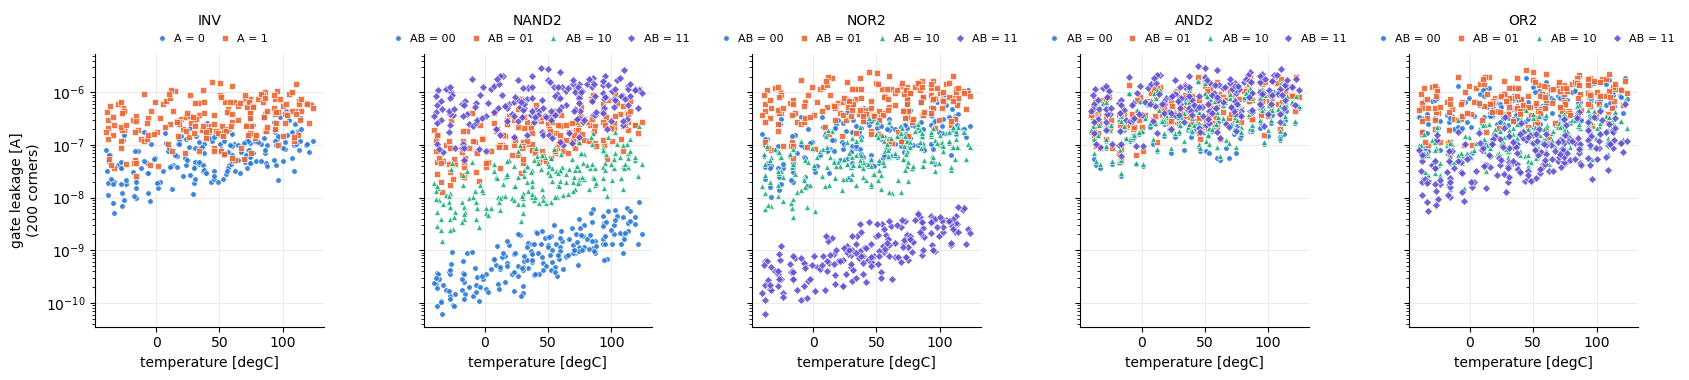

In [13]:
COLORS = {"0": "#2a78d6", "1": "#eb6834", "00": "#2a78d6", "01": "#eb6834", "10": "#1baf7a", "11": "#6250d6"}
MARKERS = {"0": "o", "1": "s", "00": "o", "01": "s", "10": "^", "11": "D"}
fig, ax = plt.subplots(1, 5, figsize=(17, 3.9), sharey=True)
for a, gate in zip(ax, GATES):
    for pat in PATTERNS[gate]:
        d = gate_spice[(gate_spice["gate"] == gate) & (gate_spice["pattern"] == pat)]
        a.plot(d["temp"], d["leak_total"], MARKERS[pat], ms=4, color=COLORS[pat], mec="white", mew=0.5, alpha=0.9, label=f"AB = {pat}" if len(pat) == 2 else f"A = {pat}")
    a.set_yscale("log"); a.set_xlabel("temperature [degC]")
    a.grid(color="0.92", lw=0.8); a.set_axisbelow(True); a.spines[["top", "right"]].set_visible(False)
    a.legend(title=gate.upper(), frameon=False, fontsize=8, title_fontsize=10, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(PATTERNS[gate]), handletextpad=0.1, columnspacing=0.8)
ax[0].set_ylabel("gate leakage [A]\n(200 corners)")
fig.tight_layout()
fig.savefig(RESULT_DIR / "gate_spice_leakage.png", dpi=110)
plt.show()

## 9. Does the leakage definition matter?
Relative difference between the two stored definitions, `leak_total / leak_supply - 1`, over the 200 corners (median and largest in magnitude). It is non-zero only when an input is held at VDD, and large only where the supply current itself is tiny.

In [14]:
rel = (gate_spice["leak_total"] / gate_spice["leak_supply"] - 1).rename("rel")
diff = gate_spice.assign(rel=rel).groupby(["gate", "pattern"], sort=False)["rel"].agg(median="median", largest=lambda s: s.abs().max()) * 100
diff.round(3).rename(columns={"median": "median [%]", "largest": "largest |.| [%]"})

median [%]  largest |.| [%]
gate  pattern                             
inv   0             0.000            0.000
      1             0.029            0.466
nand2 00            0.000            0.000
      01            0.126            1.782
      10            0.002            0.022
      11            0.072            1.146
nor2  00            0.000            0.000
      01            0.015            0.219
      10            0.154            2.953
      11           26.398         1129.282
and2  00            0.000            0.000
      01            0.042            0.572
      10            0.000            0.002
      11            0.061            0.941
or2   00            0.000            0.000
      01            0.013            0.178
      10            0.060            0.858
      11            0.237            3.440

## Summary of the gate-level reference
* **3,600 operating points** (18 cases x 200 corners) simulated in well under a minute; none missing, none duplicated, none rejected. The 200 corners are in `data/corners.csv`, the results in `data/gate_spice.csv`, one example netlist per gate in `netlists/gate_<gate>.cir`, the sizing (`XX = 2`) in `data/gate_sizing.json`.
* **Checks passed:** every output within 30 mV of its rail (largest deviation 29.2 mV), the four source currents sum to at most 2.0e-15 A, 12 points re-simulated alone reproduce the batch exactly, and the supply delivers current in every point.
* **Leakage ranges over 4.7 decades:** from 6.1e-11 A (NAND2 00 at -33 degC, VDD 0.83 V) to 3.1e-6 A (AND2 11 at 44 degC, VDD 0.94 V). The median of a case lies between 8.7e-10 A (NAND2 00) and 6.7e-7 A (OR2 01). Within one case the 200 corners spread the leakage by a factor of 40 (OR2 01) to 151 (NAND2 10), through VDD, temperature and process together; temperature alone explains 8 % to 65 % of the variance of the log leakage, depending on the case (section 8).
* **The input pattern matters as much as the corner:** the median leakage of NAND2 changes by a factor of about 670 between 00 and 11, and that of NOR2 by about 640 between 11 and 01, because in NAND2 00 the leakage path is a series stack of two OFF NMOS (the stack effect lowers it) while in 11 it is the two parallel OFF PMOS with the full supply across them (and the same, mirrored, for NOR2).
* **Leakage definition:** `leak_supply` and `leak_total` agree to within 3.5 % in 17 of the 18 cases. In **NOR2 11** they differ by a median of 26 % (up to 1,129 %; more than 5 % in 169 of the 200 corners), because the supply current of that state is the smallest of all (median 6.9e-10 A) and the gate currents of the two inputs at VDD (median 8.1e-11 A each, up to 6.0e-10 A) are then comparable to it. The definition therefore has to be stated with every result; `leak_total` is used here.
* The ML side of Part B needs the node voltages recorded here: `v_out`, `v_x`, `v_y`, `v_n` and the inputs give the terminal voltages of every transistor.

Next: notebook 05 (gate-level ML predictor, using the four saved models, with an oracle check of the composition) and the 18-row gate results table.